# Imports

In [7]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import random
import seaborn as sns
import pandas as pd
from tqdm import tqdm
from ultralytics import YOLO
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Pathing and Configuration

In [8]:
SELECTED_MODEL = 'yolov8m'

WS_PATH = os.path.dirname(os.getcwd())
SRC_PATH = os.path.join(WS_PATH, 'src')
IMAGE_DIR = os.path.join(SRC_PATH, 'dim_images')
RESULT_PATH = os.path.join(SRC_PATH, 'training_results')
MODEL_PATH = os.path.join(RESULT_PATH, SELECTED_MODEL, 'weights', 'best.pt')

N_SAMPLES = 3  # For random predictions
CONF_THRESHOLD = 0.25
CLASS_NAMES = [
    'A',
    'B',
    'C',
    'D',
    'E',
    'F',
    'G',
    'H',
    'I',
    'J',
    'K',
    'L',
    'M',
    'N',
    'O',
    'P',
    'Q',
    'R',
    'S',
    'T',
    'U',
    'V',
    'W',
    'X',
    'Y',
    'Z',
    'apa',
    'ayah',
    'cinta',
    'halo',
    'hati_hati',
    'ibu',
    'jangan',
    'kakak',
    'kakek',
    'kamu',
    'kerja',
    'maaf',
    'makan',
    'marah',
    'minum',
    'mobil',
    'motor',
    'nenek',
    'rumah',
    'sahabat',
    'sakit',
    'saya',
    'sedih',
    'senang',
    'siapa',
    'takut',
    'terima_kasih',
    'tidur',
    'tolong',
    'uang',
    'background'
]

BACKGROUND_IDX = len(CLASS_NAMES)

# Model Predicts Testing Data

In [9]:
# Load model
model = YOLO(MODEL_PATH)

# Read image files
image_paths = []
for label_folder in os.listdir(IMAGE_DIR):
    label_path = os.path.join(IMAGE_DIR, label_folder)
    if os.path.isdir(label_path):
        for f in os.listdir(label_path):
            if f.endswith((".jpg", ".png", ".jpeg")):
                image_paths.append((os.path.join(label_path, f), label_folder))

print(f"Found {len(image_paths)} images")

# Evaluation initialization
y_true = []
y_pred = []

# Inferencing process
for image_path, gt_label_name in tqdm(image_paths):

    # Ground truth

    # Label normalization
    gt_label_name = gt_label_name.replace(" ", "_")

    if gt_label_name not in CLASS_NAMES:
        print(f"Unknown label: {gt_label_name}")
        continue

    gt_label = CLASS_NAMES.index(gt_label_name)

    # Model prediction
    results = model.predict(
        image_path,
        conf=CONF_THRESHOLD,
        verbose=False
    )[0]

    if len(results.boxes) == 0:  # If no detection
        y_true.append(gt_label)
        y_pred.append(BACKGROUND_IDX)

        continue

    # Get best prediction
    pred_classes = results.boxes.cls.cpu().numpy()
    pred_confs = results.boxes.conf.cpu().numpy()

    best_idx = np.argmax(pred_confs)

    pred_label = int(pred_classes[best_idx])

    if pred_label >= len(CLASS_NAMES):
        pred_label = BACKGROUND_IDX

    # Save labels
    y_true.append(gt_label)
    y_pred.append(pred_label)

Found 1680 images


100%|██████████| 1680/1680 [04:57<00:00,  5.64it/s]


# Prediction Results

In [10]:
# Evaluation metrics
accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

print("\n==============================")
print("EVALUATION RESULTS")
print("==============================")

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")


print("\nClassification Report")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=CLASS_NAMES,
        zero_division=0
    )
)


EVALUATION RESULTS
Accuracy  : 0.8327
Precision : 0.9466
Recall    : 0.8327
F1-Score  : 0.8735

Classification Report
              precision    recall  f1-score   support

           A       1.00      1.00      1.00        30
           B       1.00      0.83      0.91        30
           C       1.00      0.83      0.91        30
           D       1.00      0.77      0.87        30
           E       0.89      0.57      0.69        30
           F       0.89      0.53      0.67        30
           G       1.00      0.57      0.72        30
           H       1.00      0.93      0.97        30
           I       1.00      0.80      0.89        30
           J       0.88      0.50      0.64        30
           K       0.79      0.90      0.84        30
           L       1.00      0.67      0.80        30
           M       1.00      0.77      0.87        30
           N       0.88      0.97      0.92        30
           O       1.00      0.70      0.82        30
           P    

# Confusion Matrix

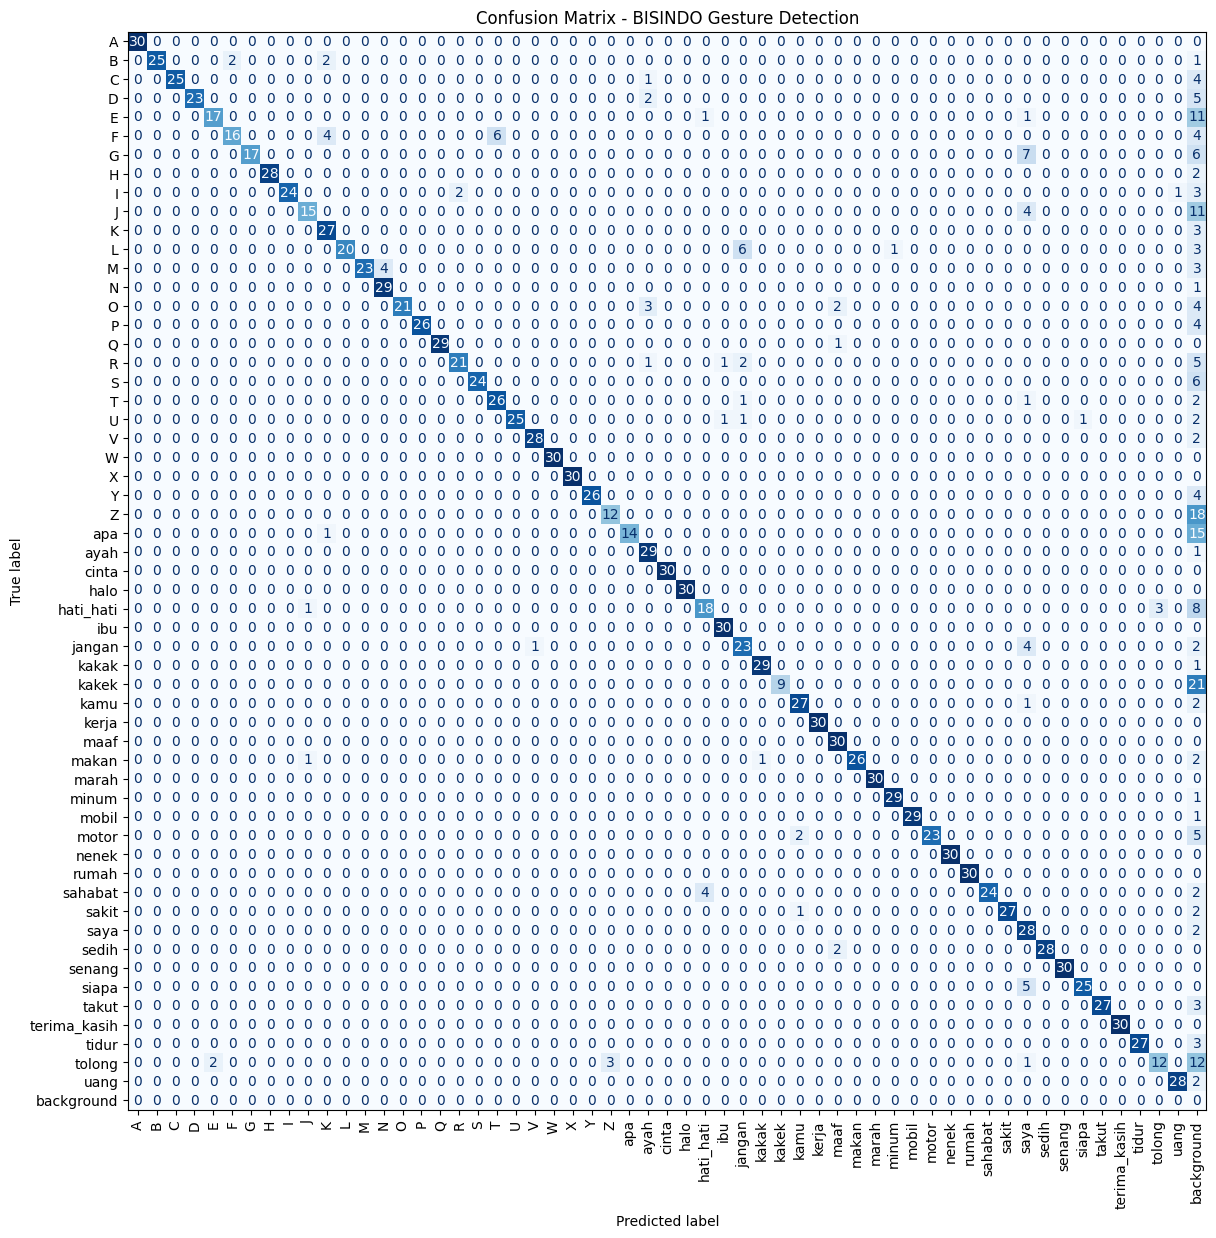

In [11]:
cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(14,14))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
)

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=90,
    colorbar=False
)

plt.title("Confusion Matrix - BISINDO Gesture Detection")

plt.show()

# Random Predictions

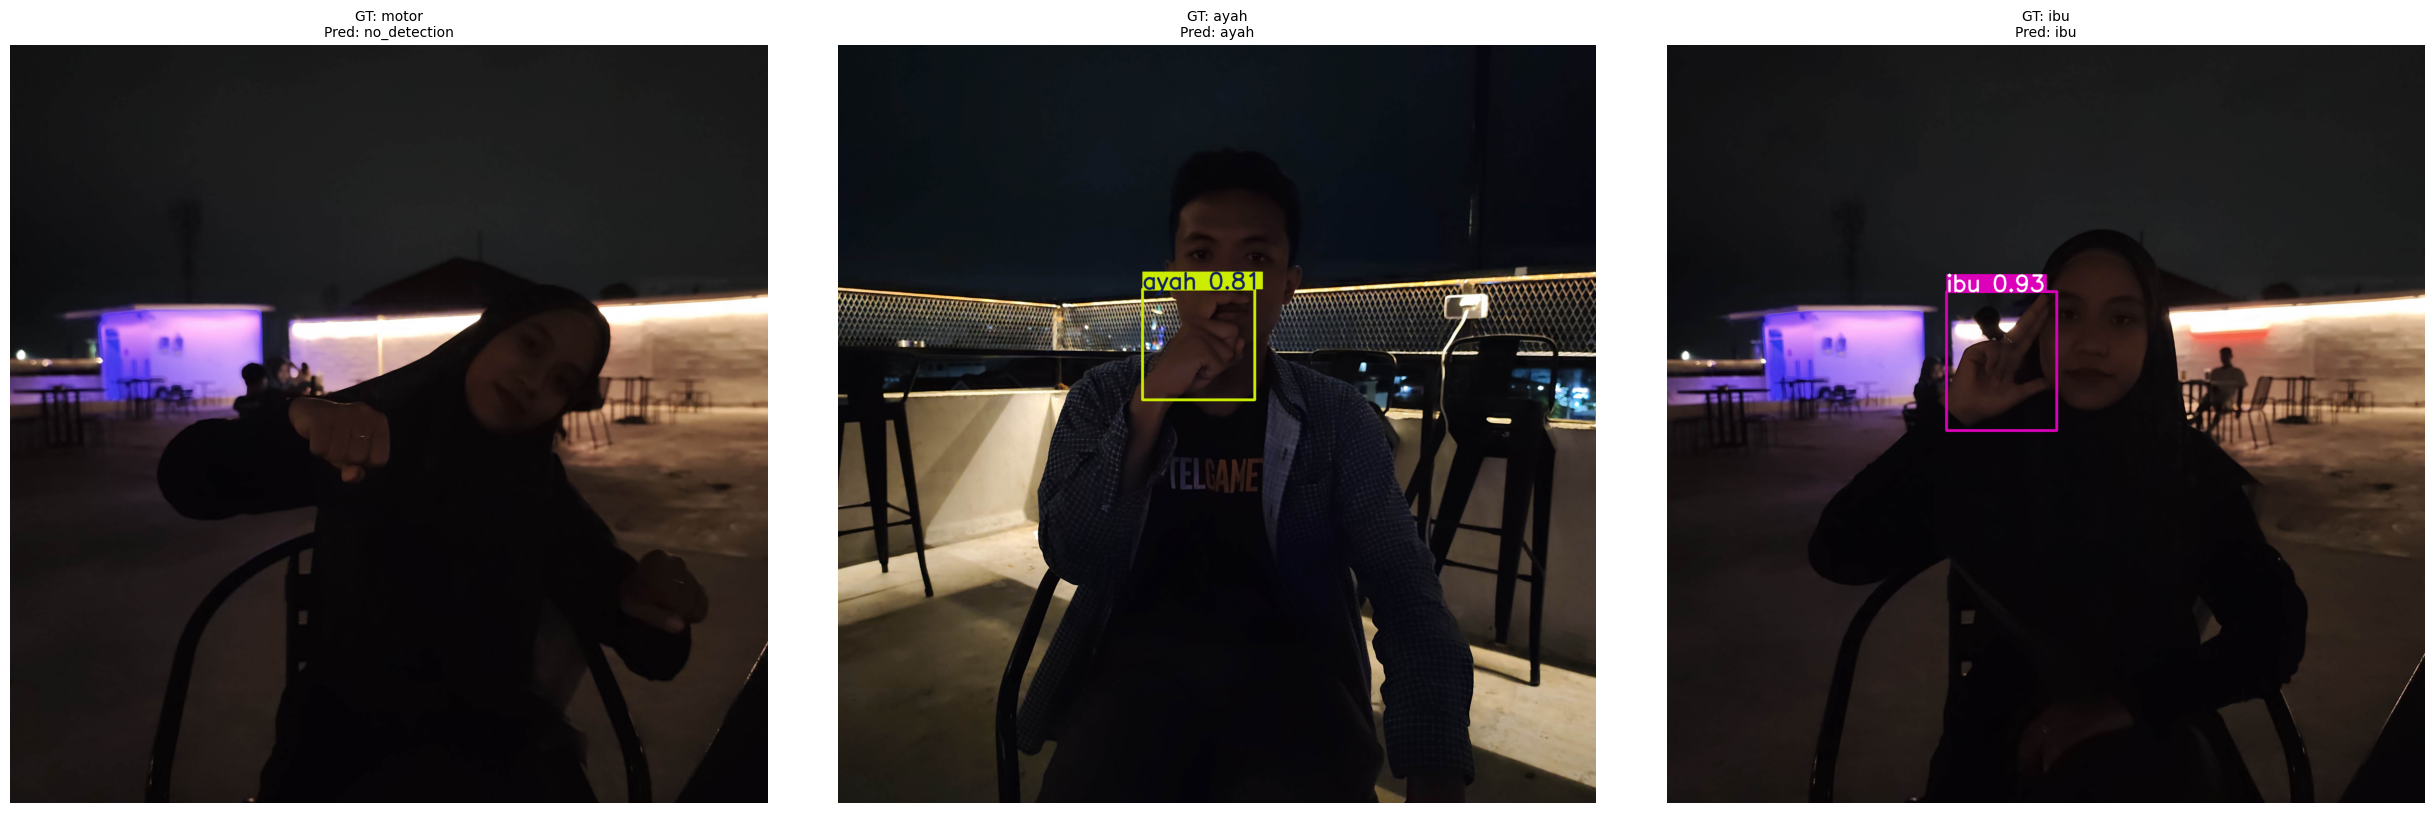

In [ ]:
samples = random.sample(
    image_paths,
    min(N_SAMPLES, len(image_paths))
)

fig, axes = plt.subplots(1, len(samples), figsize=(25, 8))

if len(samples) == 1:
    axes = [axes]

for ax, (image_path, gt_label_name) in zip(axes, samples):

    results = model.predict(
        image_path,
        conf=CONF_THRESHOLD,
        verbose=False
    )[0]

    # Draw result
    plotted = results.plot()

    plotted = cv2.cvtColor(
        plotted,
        cv2.COLOR_BGR2RGB
    )

    gt_label = gt_label_name

    if len(results.boxes) > 0:
        pred_class = int(results.boxes.cls.cpu().numpy()[0])
        pred_label = CLASS_NAMES[pred_class]
    else:
        pred_label = "no_detection"

    ax.imshow(plotted)

    ax.set_title(
        f"GT: {gt_label}\nPred: {pred_label}",
        fontsize=10
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

In [23]:
test = pd.DataFrame([y_pred, y_true]).T
test['error'] = test[0] == test[1]
test[test['error'] == False]

,0,1,error
33,10,26,False
36,57,26,False
37,57,26,False
45,57,26,False
48,57,26,False
...,...,...,...
1670,57,25,False
1672,57,25,False
1675,57,25,False
1678,57,25,False
